# sharpe-b3: análise explicada

Este notebook percorre as mesmas etapas do `main.py`, uma de cada vez, com a explicação de cada conceito.
Ele usa as funções da pasta `src/` e os dados já salvos em `data/` (se os arquivos não existirem, eles são baixados).

In [1]:
import os
import sys

# O notebook fica em notebooks/, então subimos uma pasta para achar src/ e data/.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
from IPython.display import Image, display

import main
from src import coleta, conclusoes, graficos, metricas, tratamento

pd.options.display.float_format = "{:.4f}".format
main.criar_pastas()
graficos.configurar_estilo()

## 1. Coleta

- **Preços**: Yahoo Finance, coluna `Adj Close` (fechamento ajustado). O ajuste desconta dividendos, JCP, desdobramentos e grupamentos. Sem ele, o dia em que a ação paga dividendo pareceria uma queda, e o retorno de quem ficou com o papel seria subestimado.
- **CDI**: série 12 do SGS (Banco Central), em % ao dia. É a taxa livre de risco usada no Sharpe.
- O Ibovespa é um índice de retorno total (já reinveste os proventos), então a comparação com preços ajustados é justa.

In [2]:
data_inicio, data_fim = main.definir_periodo()
precos_brutos = coleta.obter_precos(
    main.TICKERS, data_inicio, data_fim, os.path.join(main.PASTA_BRUTOS, "precos_brutos.csv"))
cdi_bruto = coleta.obter_cdi(
    data_inicio, data_fim, os.path.join(main.PASTA_BRUTOS, "cdi_bruto.csv"))
precos_brutos.tail()

  Preços lidos do cache: data\brutos\precos_brutos.csv
  CDI lido do cache: data\brutos\cdi_bruto.csv


,PETR4,VALE3,ITUB4,BBDC4,BBAS3,WEGE3,ABEV3,MGLU3,RENT3,SUZB3,IBOV
data,,,,,,,,,,,
2026-10-30,52.7100,62.0200,38.6718,13.8406,16.4700,48.3600,14.6000,5.3500,27.8500,50.1400,167922.0000
2026-11-03,50.7100,60.2500,38.4900,13.5610,16.1900,49.1700,14.7000,5.0900,27.4100,51.1800,165529.0000
2026-11-04,47.1200,62.3500,39.7100,14.0600,16.4900,50.0500,15.2500,5.5000,29.4600,52.3500,167564.0000
2026-11-05,45.9500,62.6700,39.9700,13.7700,16.4900,48.3000,15.4800,5.4300,29.0700,52.2900,166192.0000
2026-11-06,45.3000,64.0400,40.5300,14.2000,17.1300,48.1900,15.4800,5.6100,30.2900,53.4000,168499.0000


## 2. Tratamento

Decisões:

1. **Calendário**: ficam só os dias em que o Ibovespa tem cotação (pregões da B3).
2. **Faltantes**: repetir o último preço conhecido (forward fill), por no máximo 5 pregões. Equivale a assumir retorno zero no dia sem negócio. Nunca usamos o preço seguinte (backward fill), porque seria usar informação do futuro.
3. **CDI**: o CDI rende em dias úteis bancários, que não são idênticos aos pregões. Por isso montamos um índice acumulado do CDI e medimos a variação dele entre um pregão e o seguinte.

O relatório abaixo mostra, por ativo, quantos dias faltaram e o maior buraco.

In [3]:
precos, relatorio = tratamento.tratar_precos(precos_brutos, main.BENCHMARK)
retornos_cdi = tratamento.alinhar_cdi(cdi_bruto, precos.index)
relatorio

  Nenhum ticker veio vazio.
  Linhas removidas por ainda terem valor faltante: 0


,dias_com_preco,dias_faltantes,primeira_data,maior_buraco
ativo,,,,
PETR4,1247,0,2021-11-09,0
VALE3,1247,0,2021-11-09,0
ITUB4,1247,0,2021-11-09,0
BBDC4,1247,0,2021-11-09,0
BBAS3,1247,0,2021-11-09,0
WEGE3,1247,0,2021-11-09,0
ABEV3,1247,0,2021-11-09,0
MGLU3,1247,0,2021-11-09,0
RENT3,1247,0,2021-11-09,0


## 3. Retorno simples e retorno logarítmico

- **Simples**: `P_hoje / P_ontem - 1`. É o retorno que o investidor de fato vê. Para acumular no tempo, multiplica-se `(1 + r)`.
- **Log**: `ln(P_hoje / P_ontem)`. Para acumular no tempo, basta somar.

Para variações pequenas os dois são quase iguais. A célula abaixo mostra que somar os retornos log e aplicar a exponencial chega no mesmo retorno acumulado dos preços.

In [4]:
retornos = metricas.calcular_retorno_simples(precos)
retornos_log = metricas.calcular_retorno_log(precos)

comparacao = pd.DataFrame({
    "acumulado_pelos_precos": precos.iloc[-1] / precos.iloc[0] - 1,
    "produto_dos_simples": (1 + retornos).prod() - 1,
    "exp_da_soma_dos_log": np.exp(retornos_log.sum()) - 1,
})
comparacao

,acumulado_pelos_precos,produto_dos_simples,exp_da_soma_dos_log
PETR4,4.7500,4.7500,4.7500
VALE3,0.4685,0.4685,0.4685
ITUB4,1.8017,1.8017,1.8017
BBDC4,0.1850,0.1850,0.1850
BBAS3,0.6814,0.6814,0.6814
WEGE3,0.4656,0.4656,0.4656
ABEV3,0.1378,0.1378,0.1378
MGLU3,-0.9501,-0.9501,-0.9501
RENT3,-0.2656,-0.2656,-0.2656
SUZB3,0.2481,0.2481,0.2481


## 4. Métricas por ativo

| Métrica | Como é calculada |
|---|---|
| Retorno acumulado | último preço / primeiro preço - 1 |
| Retorno anualizado | (1 + acumulado) ^ (252 / número de pregões) - 1 |
| Volatilidade anualizada | desvio padrão dos retornos diários x raiz de 252 |
| Drawdown máximo | menor valor de (preço / maior preço até o dia - 1) |
| Sharpe | (retorno anualizado - CDI anualizado) / volatilidade anualizada |
| Beta | covariância(ativo, Ibovespa) / variância(Ibovespa) |

A raiz de 252 aparece porque, se os retornos diários forem independentes, a **variância** cresce em proporção ao tempo. Como a volatilidade é a raiz da variância, ela cresce com a raiz do tempo.

In [5]:
tabela, cdi_anualizado = metricas.montar_tabela_resumo(precos, retornos_cdi, main.BENCHMARK)
print("CDI anualizado no período: {:.2%}".format(cdi_anualizado))
tabela

CDI anualizado no período: 12.92%


,retorno_acumulado,retorno_anualizado,volatilidade_anualizada,drawdown_maximo,data_pico,data_fundo,sharpe,beta
ativo,,,,,,,,
PETR4,4.7500,0.4244,0.3156,-0.3910,2022-10-21,2022-12-14,0.9357,0.8425
ITUB4,1.8017,0.2317,0.2438,-0.2376,2022-10-21,2022-12-13,0.4203,0.9951
BBAS3,0.6814,0.1108,0.3063,-0.4300,2025-05-14,2026-11-03,-0.0599,1.1254
IBOV,0.5966,0.0993,0.1867,-0.2093,2022-04-01,2022-07-14,-0.1602,1.0000
WEGE3,0.4656,0.0804,0.3034,-0.3819,2024-12-11,2025-08-19,-0.1608,0.5720
VALE3,0.4685,0.0808,0.2893,-0.3815,2023-01-26,2025-04-08,-0.1671,0.7112
SUZB3,0.2481,0.0458,0.2790,-0.3801,2022-03-18,2023-04-27,-0.2986,0.1860
BBDC4,0.1850,0.0349,0.3155,-0.3943,2026-10-06,2026-11-03,-0.2987,1.1910
RENT3,-0.2656,-0.0605,0.4295,-0.5953,2022-11-04,2025-02-27,-0.4417,1.6737


## 5. Correlação

A correlação mede se dois ativos costumam subir e cair juntos (perto de +1) ou de forma independente (perto de 0). É ela que define o ganho de diversificação: juntar ativos pouco correlacionados reduz a volatilidade da carteira.

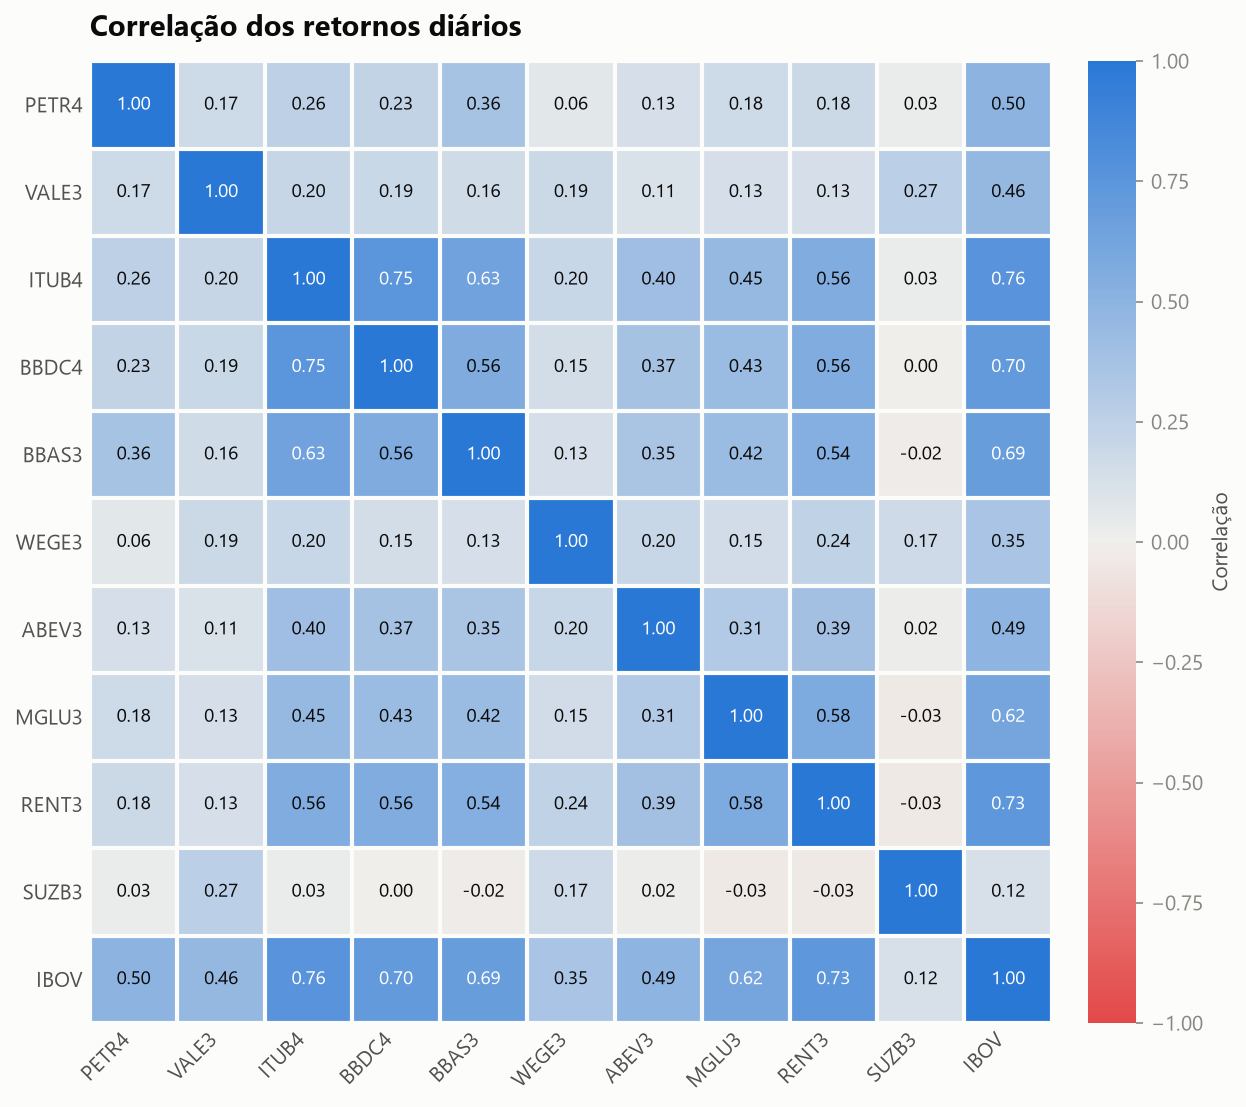

In [6]:
correlacao = metricas.calcular_matriz_correlacao(retornos)
caminho = os.path.join(main.PASTA_OUTPUTS, "03_correlacao.png")
graficos.plotar_heatmap_correlacao(correlacao, caminho)
display(Image(caminho, width=650))

## 6. Gráficos

Retorno acumulado (base 100) e drawdown usam um painel por ação, com o Ibovespa em cinza como referência.

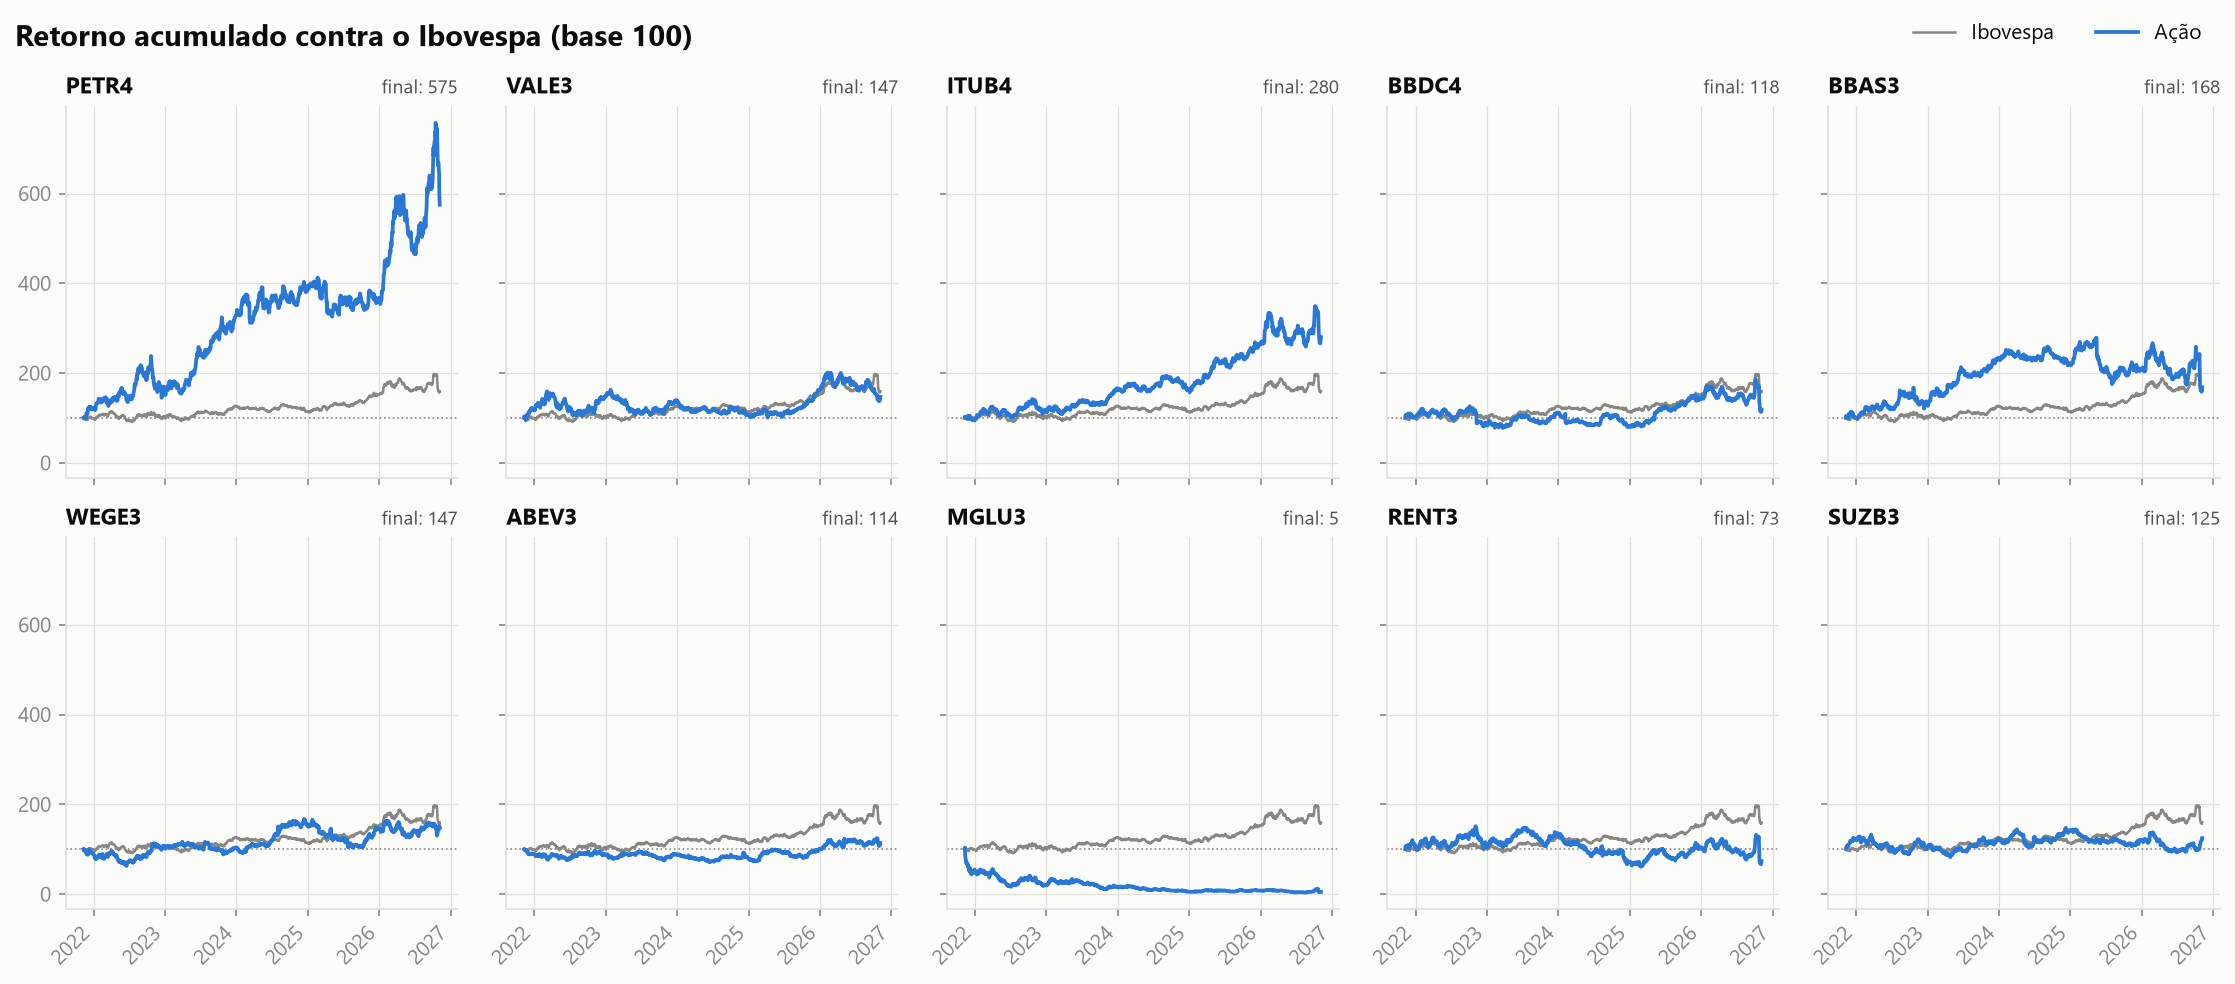

In [7]:
base_100 = metricas.calcular_base_100(precos)
caminho = os.path.join(main.PASTA_OUTPUTS, "01_retorno_acumulado.png")
graficos.plotar_retorno_acumulado(base_100, main.BENCHMARK, caminho)
display(Image(caminho))

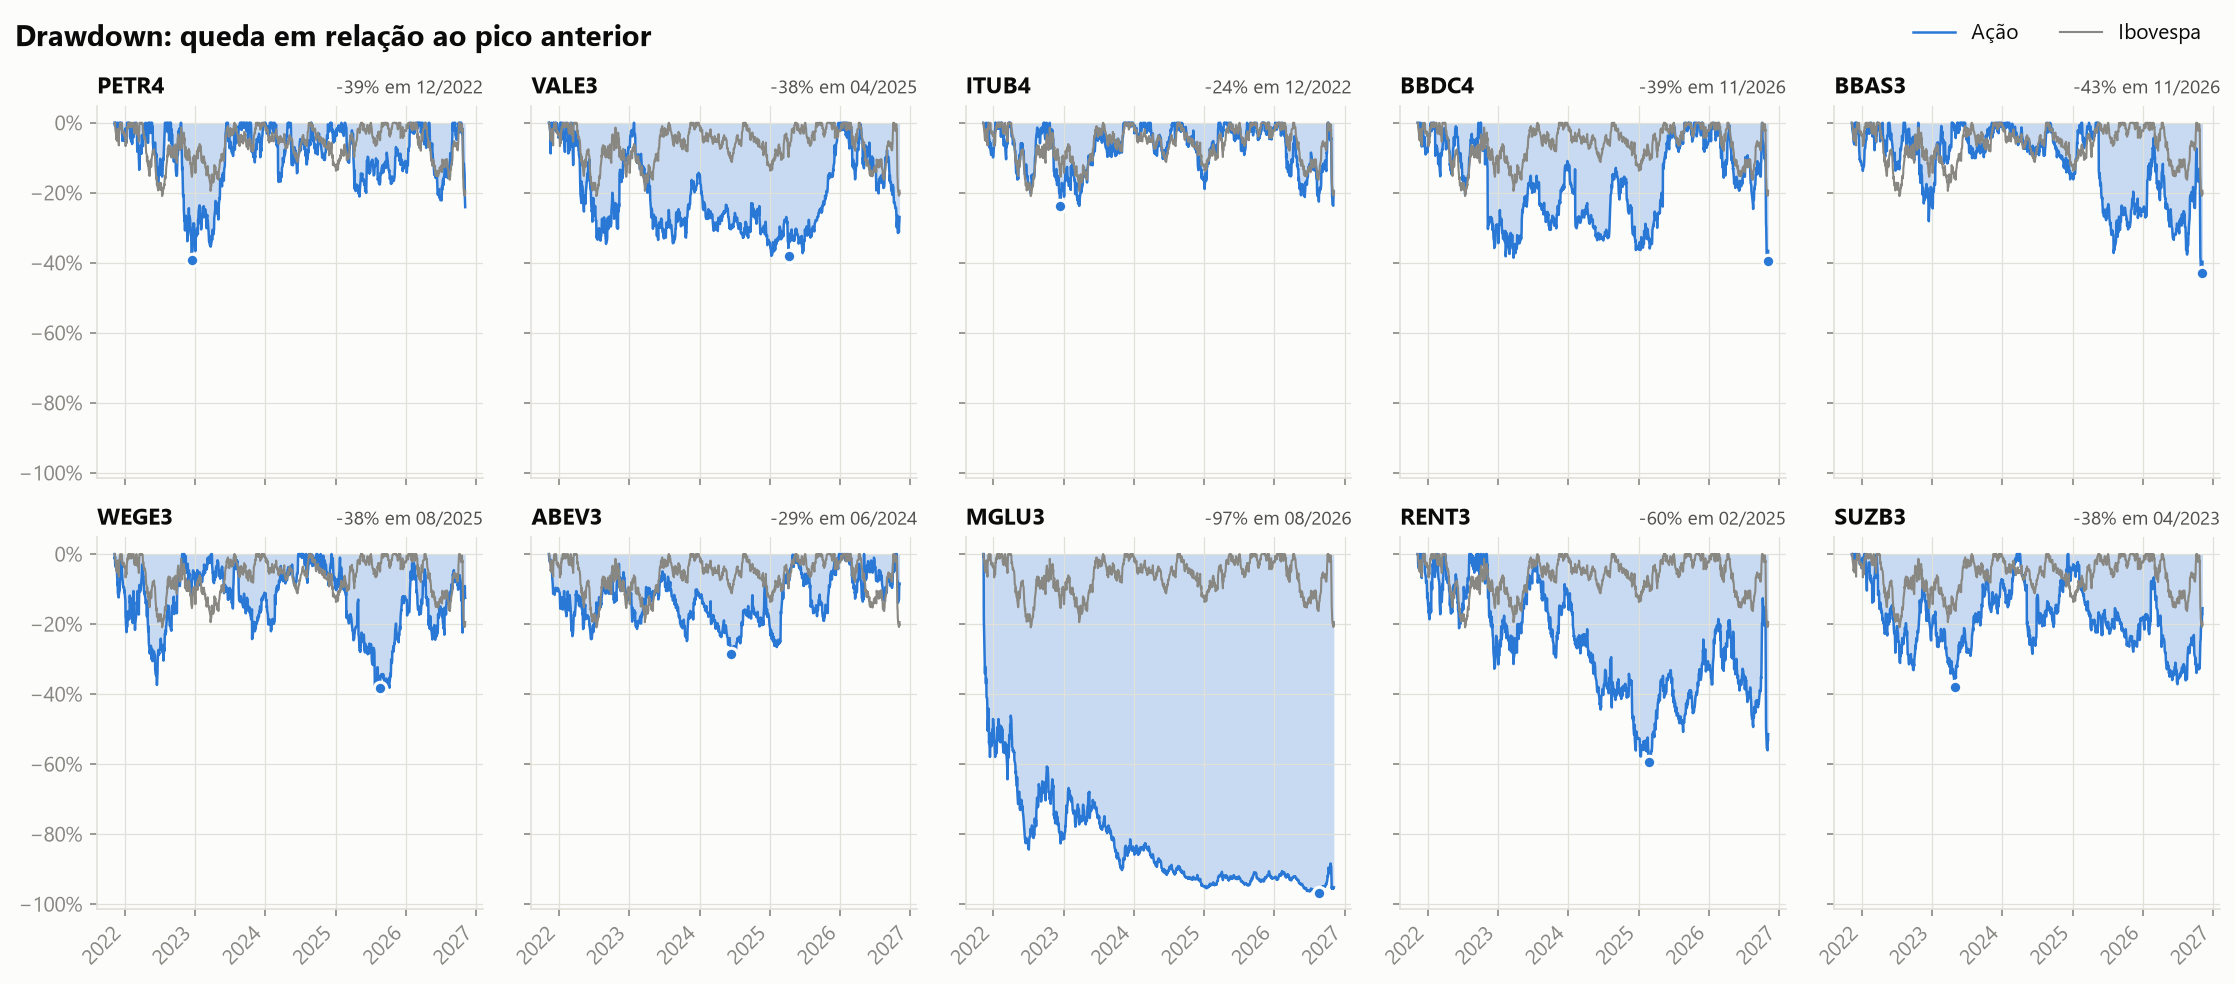

In [8]:
drawdown = metricas.calcular_curva_drawdown(precos)
caminho = os.path.join(main.PASTA_OUTPUTS, "02_drawdown.png")
graficos.plotar_drawdown(drawdown, tabela, main.BENCHMARK, caminho)
display(Image(caminho))

No gráfico de risco x retorno, o ideal é estar em cima e à esquerda (muito retorno, pouca volatilidade). A linha tracejada é o CDI: quem está abaixo dela tem Sharpe negativo.

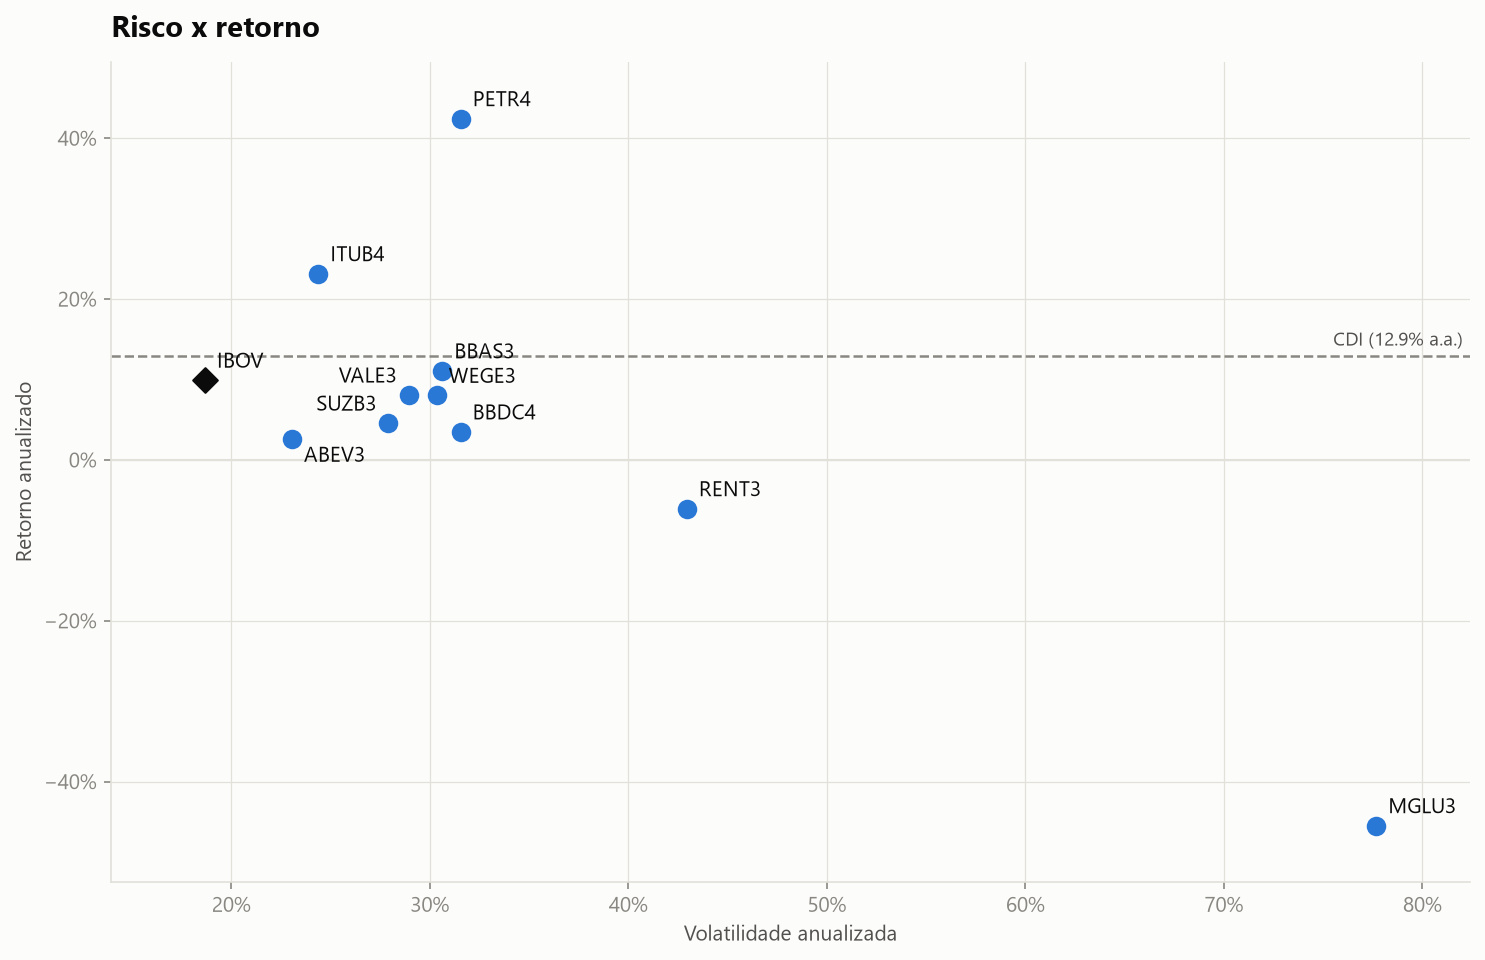

In [9]:
caminho = os.path.join(main.PASTA_OUTPUTS, "04_risco_retorno.png")
graficos.plotar_risco_retorno(tabela, cdi_anualizado, main.BENCHMARK, caminho)
display(Image(caminho, width=750))

A volatilidade móvel mostra que o risco não é constante: ela se concentra em alguns períodos (agrupamento de volatilidade).

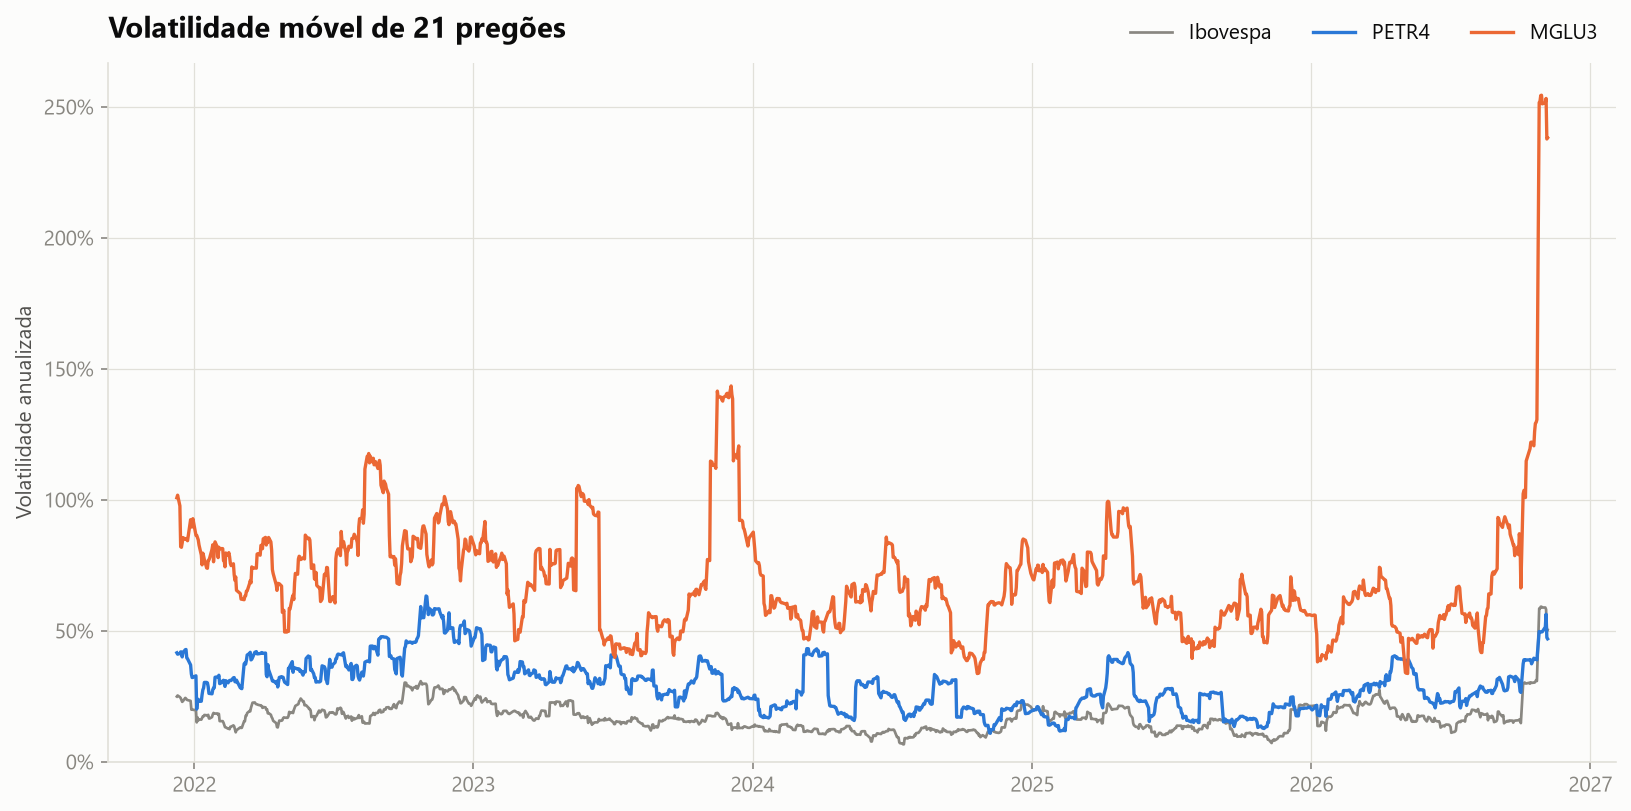

In [10]:
volatilidade_movel = metricas.calcular_volatilidade_movel(retornos, janela=21)
caminho = os.path.join(main.PASTA_OUTPUTS, "05_volatilidade_movel.png")
graficos.plotar_volatilidade_movel(
    volatilidade_movel, main.ATIVOS_VOLATILIDADE_MOVEL, main.BENCHMARK, caminho)
display(Image(caminho, width=850))

## 7. Conclusões

O texto é gerado a partir dos números, então acompanha os dados se eles forem atualizados.

In [11]:
observacoes = conclusoes.gerar_conclusoes(
    tabela, correlacao, retornos, cdi_anualizado, main.BENCHMARK)
for observacao in observacoes:
    print(observacao)
    print()

1. Melhor relação risco/retorno: PETR4 teve o maior Sharpe (0,94), com retorno anualizado de 42,4% e volatilidade de 31,6%. No outro extremo, MGLU3 teve o pior Sharpe (-0,75).

2. Comparação com o CDI: a taxa livre de risco rendeu 12,9% ao ano no período. 2 das 10 ações tiveram Sharpe positivo (renderam mais que o CDI), e o Ibovespa rendeu 9,9% ao ano (Sharpe de -0,16).

3. Maior drawdown: MGLU3 caiu 96,7% entre o pico de 11/2021 e o fundo de 08/2026. Para comparação, o drawdown máximo do Ibovespa foi de 20,9%, e o pior dia do índice foi 26/10/2026 (-13,9%).

4. Correlação: o par mais correlacionado foi ITUB4 e BBDC4 (0,75), e o menos correlacionado foi RENT3 e SUZB3 (-0,03). Pares com correlação baixa são os que mais ajudam a diversificar uma carteira.

5. Risco: MGLU3 foi a ação mais volátil (77,7% ao ano) e ABEV3 a menos volátil (23,1%). O maior beta foi o de MGLU3 (2,56) e o menor o de SUZB3 (0,19).

